In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
gold = pd.read_csv(
    "../../data/Xaira/HEK293T_pseudobulk_sum_AllPertsByExpressedGenes.tsv.Percent1",
    sep="\t", header=None, names=["ppi", "score"]
)
gold_pair = set(gold["ppi"])
gold_gene = pd.Index(pd.unique(gold["ppi"].str.split("__", n=1, expand=True).values.ravel()))

In [3]:
def load_pairs_in_use(name):
    if name.startswith("FromRaw"):
        path = f"../../result/HEK293T_HCT116/ppi/{name}.ppi"
    else:
        path = f"../../result/HEK293T_HCT116/ppi/{name}.ppi.Percent1"
    return pd.read_csv(path, sep="\t", header=None, names=["ppi", "score"])


def testable_hits(pairs):
    """
    Rank-ordered 0/1 gold hits over the pairs whose two genes the screen both perturbed.
    """
    pair_gene = pairs.str.split("__", n=1, expand=True)
    testable = pairs[pair_gene[0].isin(gold_gene) & pair_gene[1].isin(gold_gene)]
    return testable.isin(gold_pair).to_numpy()


def enrichment_curve(hit, n_bin=100):
    """
    Cumulative fold enrichment at every 1% of the ranked good pairs
    """
    cut = np.ceil(np.arange(1, n_bin + 1) / n_bin * len(hit)).astype(int)
    return np.cumsum(hit)[cut - 1] / cut / hit.mean()

In [4]:
file_list = [
    "FromInputConcat_HEK293T",
    "AEconcat_HEK293T",
    "GPScombine_HEK293T",
    "promergesubtract_HCT116anchor_HEK293T",
    "promergeclub_HCT116anchor_HEK293T",
]
label_list = ["Init emb", "Autoencoder", "CL (context-agnostic) ", "Subtraction", "ProMERGE"]
color_list = ["#b0b0b0", "tab:brown", "tab:cyan", "tab:orange", "tab:red"]
marker_list = ["o", "o", "o", "o", "o"]

hit_list = [testable_hits(load_pairs_in_use(name)["ppi"]) for name in file_list]
curve_list = [enrichment_curve(hit) for hit in hit_list]

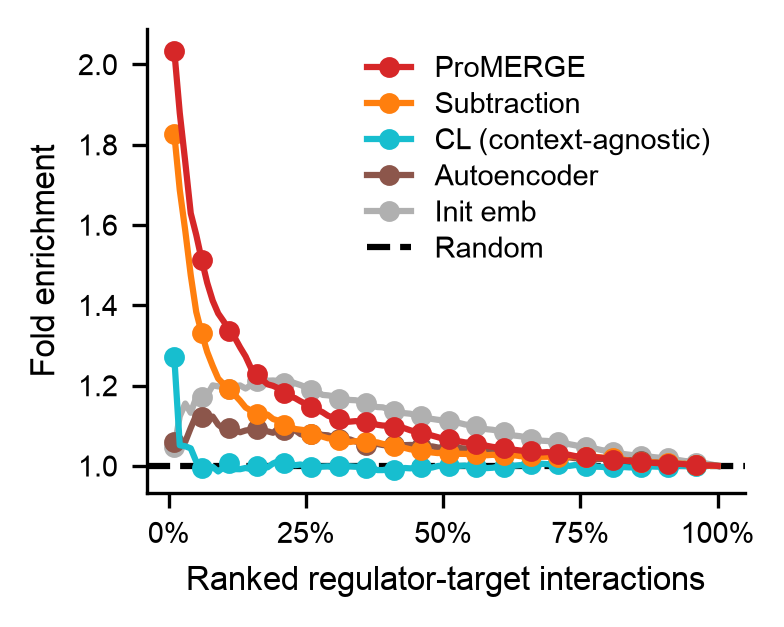

In [5]:
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, ax = plt.subplots(figsize=(2.4, 2.1), dpi=300)
fig.subplots_adjust(left=0.14, right=0.97, bottom=0.245, top=0.98)

# random
ax.axhline(1, color='black', ls='--', zorder=0, label="Random")

# main plot
x = np.arange(1, 101)
for curve, label, color, marker in zip(curve_list, label_list, color_list, marker_list):
    ax.plot(x, curve, f'{marker}-', color=color, markevery=5, label=label, ms=4)

# axis and tick
ax.set_xlabel("Ranked regulator-target interactions", fontsize=8)
ax.set_ylabel("Fold enrichment", fontsize=8)
ax.set_xticks([0, 25, 50, 75, 100], ['0%', '25%', '50%', '75%', '100%'])
ax.spines[['right', 'top']].set_visible(False)

# legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1],
    labels[::-1],
    markerscale=1,
    handlelength=1.5,
    labelspacing=0.3,
    frameon=False
)

plt.savefig("./figS7_enrichment_pert-response.pdf", bbox_inches='tight', transparent=True)

In [6]:
N_BOOT = 10000
rng = np.random.default_rng(1)

def boot_top_enrichment(hit, n_boot=N_BOOT):
    n = len(hit)
    k = int(np.ceil(n / 100))
    top = rng.binomial(k, hit[:k].mean(), size=n_boot) / k
    rest = rng.binomial(n - k, hit[k:].mean(), size=n_boot) / (n - k)
    return top / ((k * top + (n - k) * rest) / n)


top1 = dict(zip(label_list, [enrichment_curve(hit)[0] for hit in hit_list]))
boot = dict(zip(label_list, [boot_top_enrichment(hit) for hit in hit_list]))

for label in label_list:
    if label == "ProMERGE":
        continue
    
    diff = boot["ProMERGE"] - boot[label]
    p = min(
        1.0,
        2 * (min((diff <= 0).sum(), (diff >= 0).sum()) + 1) / (N_BOOT + 1)
    )
    lo, hi = np.percentile(diff, [2.5, 97.5])
    
    promerge_score = top1["ProMERGE"]
    print(
        f"ProMERGE {promerge_score:+.3f} vs {label} {top1[label]:+.3f}: "
        f"diff {promerge_score - top1[label]:+.3f} [{lo:+.3f}, {hi:+.3f}], p = {p:.3g}"
    )

ProMERGE +2.035 vs Init emb +1.046: diff +0.989 [+0.728, +1.248], p = 0.0002
ProMERGE +2.035 vs Autoencoder +1.060: diff +0.975 [+0.676, +1.276], p = 0.0002
ProMERGE +2.035 vs CL (context-agnostic)  +1.271: diff +0.764 [+0.480, +1.046], p = 0.0002
ProMERGE +2.035 vs Subtraction +1.827: diff +0.207 [-0.093, +0.503], p = 0.171
